<a href="https://colab.research.google.com/github/carolyndevadoss/MMA3001-Project/blob/main/examples/MMA3001_Temperature_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Setup successful!")

Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1
Setup successful!


In [2]:
import pandas as pd
import glob

# Find CSV files uploaded to Colab
csv_files = glob.glob("/content/*.csv")
print("Available CSV files:", csv_files)

# Load the environmental dataset
df = pd.read_csv(csv_files[0], low_memory=False)

# Check the dataset structure
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

# Display the first five rows
display(df.head())

Available CSV files: ['/content/5EnvSensor_MayToDec2024_180kRows.csv']

Dataset shape: (19821, 8)

Column names: ['id', 'sensorid', 'devicetype', 'jsondata', 'status', 'processing_errors', 'createdate', 'processdate']


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6.012002e+12,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11
1,4,6.012002e+12,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11
2,5,6.012002e+12,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11
3,16,6.012002e+12,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11
4,24,6.012002e+12,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11


In [6]:
import json

# Decode the first environmental sensor record
sample = df["jsondata"].dropna().iloc[0]
parsed = json.loads(sample)

# Identify the environmental variables available
print("Number of measurement groups:", len(parsed))

for i, group in enumerate(parsed):
    variable = group["variable"]

    print(
        f"{i+1}. {variable['name']} "
        f"({variable['unit']})"
    )

Number of measurement groups: 11
1. Battery (V)
2. Carbon dioxide (ppm)
3. Humidity (HR%)
4. Formaldehyde (µg/m3)
5. Pressure (mb)
6. Temperature (°C)
7. Light Volatile Organic Compounds (ppb)
8. Particulate matter 1 (µg/m3)
9. Particulate matter 4 (µg/m3)
10. Particulate matter 2.5 (µg/m3)
11. Particulate matter 10 (µg/m3)


In [8]:
# Extract temperature measurements from the full dataset
temperature_readings = []

for _, row in df.iterrows():
    if pd.isna(row["jsondata"]):
        continue

    try:
        groups = json.loads(row["jsondata"])

        for group in groups:
            if group["variable"]["name"] == "Temperature":
                for reading in group["values"]:
                    temperature_readings.append({
                        "sensorid": str(row["sensorid"]),
                        "timestamp": reading["time"],
                        "temperature_C": reading["value"]
                    })

    except (json.JSONDecodeError, KeyError, TypeError):
        continue

# Create a DataFrame
temp_all = pd.DataFrame(temperature_readings)

# Convert Unix timestamps into UTC datetime
temp_all["timestamp"] = pd.to_datetime(
    temp_all["timestamp"],
    unit="s",
    utc=True
)

# Display dataset information
print("Total extracted readings:", len(temp_all))
print("Unique sensors:", temp_all["sensorid"].nunique())
print("Date range:", temp_all["timestamp"].min(),
      "to", temp_all["timestamp"].max())

display(temp_all.head())


Total extracted readings: 19820
Unique sensors: 4
Date range: 2023-05-05 22:42:45+00:00 to 2024-04-07 21:25:14+00:00


,sensorid,timestamp,temperature_C
0,6012002000241.0,2023-12-11 05:52:45+00:00,23.8
1,6012002000241.0,2023-12-11 05:52:45+00:00,23.8
2,6012002000326.0,2023-12-11 05:00:57+00:00,23.8
3,6012002000777.0,2023-05-05 22:42:45+00:00,18.8
4,6012002000869.0,2024-02-29 06:04:56+00:00,24.3


In [9]:
# Count exact duplicate measurements
duplicates = temp_all.duplicated(
    subset=["sensorid", "timestamp", "temperature_C"]
).sum()

print("Total readings:", len(temp_all))
print("Exact duplicates:", duplicates)

# Remove exact duplicates and sort chronologically
temp_clean = (
    temp_all
    .drop_duplicates(
        subset=["sensorid", "timestamp", "temperature_C"]
    )
    .sort_values(["sensorid", "timestamp"])
    .reset_index(drop=True)
)

print("Readings after removing duplicates:", len(temp_clean))

# Summarise readings for each sensor
sensor_summary = (
    temp_clean.groupby("sensorid")
    .agg(
        readings=("temperature_C", "size"),
        first_reading=("timestamp", "min"),
        last_reading=("timestamp", "max")
    )
)

# Calculate intervals between consecutive measurements
temp_clean["interval_minutes"] = (
    temp_clean.groupby("sensorid")["timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

# Find the median sampling interval for each sensor
sensor_summary["median_interval_minutes"] = (
    temp_clean.groupby("sensorid")["interval_minutes"]
    .median()
)

display(sensor_summary)


Total readings: 19820
Exact duplicates: 14969
Readings after removing duplicates: 4851


,readings,first_reading,last_reading,median_interval_minutes
sensorid,,,,
6012002000241.0,1,2023-12-11 05:52:45+00:00,2023-12-11 05:52:45+00:00,NaN
6012002000326.0,1,2023-12-11 05:00:57+00:00,2023-12-11 05:00:57+00:00,NaN
6012002000777.0,1,2023-05-05 22:42:45+00:00,2023-05-05 22:42:45+00:00,NaN
6012002000869.0,4848,2024-02-29 06:04:56+00:00,2024-04-07 21:25:14+00:00,10.0


Selected sensor: 6012002000869.0
Number of readings: 4848

Temperature statistics:
count    4848.000000
mean       23.375660
std         1.225167
min        20.300000
25%        22.800000
50%        23.300000
75%        23.800000
max        28.500000
Name: temperature_C, dtype: float64

Sampling interval statistics (minutes):
count    4847.000000
mean       11.479327
std         3.550809
min         9.800000
25%        10.000000
50%        10.000000
75%        10.016667
max        20.200000
Name: interval_minutes, dtype: float64

Gaps greater than 30 minutes: 0


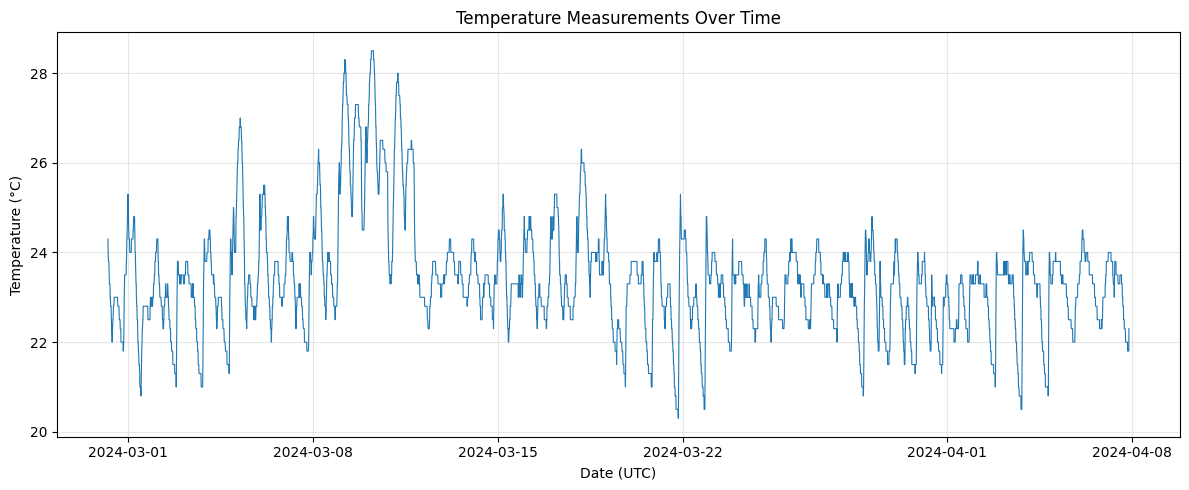

In [10]:
# Select the sensor containing the most measurements
selected_sensor = sensor_summary["readings"].idxmax()

sensor_df = (
    temp_clean[temp_clean["sensorid"] == selected_sensor]
    .copy()
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("Selected sensor:", selected_sensor)
print("Number of readings:", len(sensor_df))

# Temperature statistics
print("\nTemperature statistics:")
print(sensor_df["temperature_C"].describe())

# Investigate time intervals
print("\nSampling interval statistics (minutes):")
print(sensor_df["interval_minutes"].describe())

print("\nGaps greater than 30 minutes:",
      (sensor_df["interval_minutes"] > 30).sum())

# Plot temperature over time
plt.figure(figsize=(12, 5))
plt.plot(
    sensor_df["timestamp"],
    sensor_df["temperature_C"],
    linewidth=0.8
)

plt.title("Temperature Measurements Over Time")
plt.xlabel("Date (UTC)")
plt.ylabel("Temperature (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Intervals approximately 10 minutes: 4130
Intervals approximately 20 minutes: 717
Other intervals: 0

Duplicate timestamps: 0


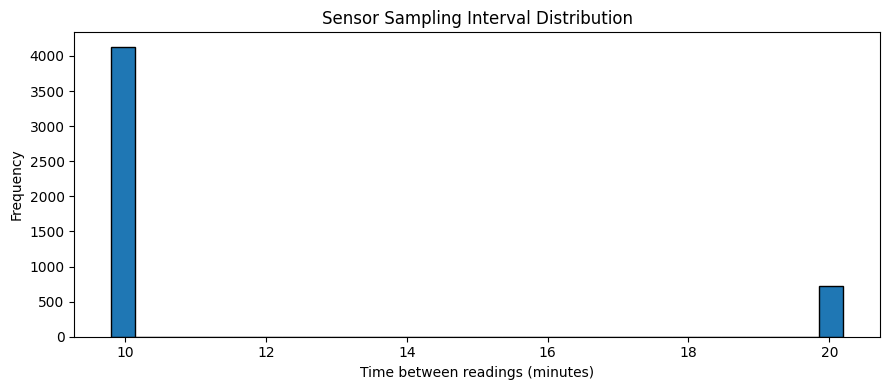

In [11]:
intervals = sensor_df["interval_minutes"].dropna()

print("Intervals approximately 10 minutes:",
      intervals.between(9.5, 10.5).sum())

print("Intervals approximately 20 minutes:",
      intervals.between(19.5, 20.5).sum())

print("Other intervals:",
      (~intervals.between(9.5, 10.5) &
       ~intervals.between(19.5, 20.5)).sum())

# Check whether timestamps are unique
print("\nDuplicate timestamps:",
      sensor_df["timestamp"].duplicated().sum())

# Plot distribution of sampling intervals
plt.figure(figsize=(9, 4))
plt.hist(intervals, bins=30, edgecolor="black")
plt.xlabel("Time between readings (minutes)")
plt.ylabel("Frequency")
plt.title("Sensor Sampling Interval Distribution")
plt.tight_layout()
plt.show()
